In [1]:
import numpy as np
import pandas as pd

In [2]:
##now for this ML model(clustering) imp features are-skills,avg_experience
#title,company, descriptions columns are not important for ML model training ; maybe it'll create 
# clusters depend upon company having more number of data scientist posts

In [3]:
##we need to make a skill matrix means each skills will be treated as a column
#then we'll add avg_experience in another column and we'll scale this column as the experience column will contain larger numbers

WORKFLOW SHOULD LOOK LIKE THIS:

Cleaned dataset
       
Skill multi-hot encoding
       
Add avg_experience
       
Scale features
       
Choose K
       
K-Means
       
Cluster assignments
       
Interpret clusters
       
Company → Cluster
       
Cluster → Skills
       
Cluster → Experience
       
Cluster → Location

we are going to use MULTI-HOT ENCODING HERE AS ONE JOB HAS TOO MANY SKILLS REQUIRED.

In [4]:
data=pd.read_csv('job.csv')

In [5]:
new_data=data[['skills','avg_experience']].copy()
new_data.head(2)

,skills,avg_experience
0,"['sas', 'machine learning', 'analytics', 'pyth...",5.0
1,"['data science', 'artificial intelligence', 'm...",NaN


In [6]:
new_data["skills"].apply(type).value_counts()

skills
<class 'str'>    153
Name: count, dtype: int64

In [7]:
import ast

new_data["skills"] = new_data["skills"].apply(ast.literal_eval)

In [8]:
import ast

def check_skills(x):
    try:
        ast.literal_eval(x)
        return True
    except:
        return False

new_data["skills"].apply(check_skills).value_counts()

skills
False    153
Name: count, dtype: int64

In [9]:
new_data.head(5)

,skills,avg_experience
0,"[sas, machine learning, analytics, python, sql...",5.0
1,"[data science, artificial intelligence, machin...",NaN
2,"[data science, artificial intelligence, machin...",NaN
3,"[data, security management, python, data analy...",4.0
4,"[artificial intelligence, machine learning, py...",NaN


In [10]:
repr(new_data["skills"].iloc[0])

"['sas', 'machine learning', 'analytics', 'python', 'sql', 'artificial intelligence', 'deep learning', 'intelligence']"

In [11]:
new_data[new_data["skills"].apply(type) == list]["skills"].iloc[0]

['sas',
 'machine learning',
 'analytics',
 'python',
 'sql',
 'artificial intelligence',
 'deep learning',
 'intelligence']

In [12]:
##here we are gonna use MULTI-HOT ENCODING HERE
from sklearn.preprocessing import MultiLabelBinarizer
m=MultiLabelBinarizer()
skill_matrix=m.fit_transform(new_data['skills'])

In [13]:
skill_matrix[0].shape

(356,)

In [14]:
skill_matrix[0]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [15]:
m.classes_

array(['3d', 'administration', 'advanced analytics', 'advanced sql',
       'aerospace', 'agentic ai', 'agile', 'agile development',
       'agile scrum', 'ai', 'ai engineer', 'ai platform', 'ai solutions',
       'aiml', 'airflow', 'algorithm development', 'algorithms',
       'amazon cloudwatch', 'aml', 'analysis', 'analytical',
       'analytical skills', 'analytics', 'ann', 'anomaly detection',
       'ansys', 'anti money laundering', 'apache', 'api design',
       'api integration', 'apis', 'app development', 'application',
       'application development', 'applied mathematics', 'architecture',
       'arima', 'artificial intelligence', 'asset management', 'ats',
       'autocad', 'autogen', 'automated testing', 'automating',
       'automation', 'automation solutions', 'aviation', 'avionics',
       'aws', 'aws bedrock', 'aws sagemaker', 'azure', 'azure cloud',
       'azure databricks', 'azure ml', 'azure openai', 'banking',
       'banking analytics', 'bayesian', 'big data', '

In [16]:
skill_matrix.shape

(153, 356)

In [17]:
skill_df = pd.DataFrame(
    skill_matrix,
    columns=m.classes_
)

skill_df.head()

,3d,administration,advanced analytics,advanced sql,aerospace,agentic ai,agile,agile development,agile scrum,ai,...,vector databases,version control,vertex,vertex ai,vision,visualization,vmware,web services,xgboost,xml
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:
##handling missing values present in avg_experience
from sklearn.impute import SimpleImputer
si=SimpleImputer(strategy='median')
si.fit_transform(new_data[['avg_experience']])

array([[ 5. ],
       [ 6. ],
       [ 6. ],
       [ 4. ],
       [ 6. ],
       [ 6. ],
       [ 6.5],
       [ 7. ],
       [14.5],
       [ 7. ],
       [ 7. ],
       [ 9. ],
       [ 4.5],
       [ 6. ],
       [13. ],
       [ 2.5],
       [ 3. ],
       [ 6. ],
       [ 3.5],
       [ 8. ],
       [ 6.5],
       [ 4. ],
       [ 4.5],
       [ 1.5],
       [ 6. ],
       [ 6.5],
       [ 7.5],
       [14.5],
       [ 8.5],
       [10.5],
       [10. ],
       [10.5],
       [10.5],
       [ 5. ],
       [ 8.5],
       [ 7. ],
       [ 3.5],
       [15. ],
       [10.5],
       [ 8. ],
       [ 9.5],
       [ 3.5],
       [ 8. ],
       [10.5],
       [ 5. ],
       [ 6. ],
       [ 5.5],
       [10.5],
       [ 7. ],
       [10.5],
       [10.5],
       [ 5. ],
       [ 9.5],
       [ 2.5],
       [ 3.5],
       [ 1. ],
       [ 6. ],
       [ 8.5],
       [ 6. ],
       [ 6.5],
       [ 7.5],
       [ 7.5],
       [ 4. ],
       [ 6.5],
       [ 6. ],
       [ 7.5],
       [10

In [19]:
new_data['avg_experience'].isnull().sum()

np.int64(10)

In [20]:
import statistics as st

new_data['avg_experience'] = new_data['avg_experience'].fillna(
    st.median(new_data['avg_experience'].dropna())
)

In [21]:
new_data['avg_experience'].isnull().sum()

np.int64(0)

In [22]:
cluster_data = pd.concat(
    [skill_df, new_data[['avg_experience']]],
    axis=1
)

In [23]:
cluster_data.shape

(153, 357)

In [24]:
cluster_data.head(15)

,3d,administration,advanced analytics,advanced sql,aerospace,agentic ai,agile,agile development,agile scrum,ai,...,version control,vertex,vertex ai,vision,visualization,vmware,web services,xgboost,xml,avg_experience
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5.0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,6.0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,6.0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4.0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,6.0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,6.0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,6.5
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,7.0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,14.5
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,7.0


SO we are gonna implement this K-Means

as we don't have any target label/column; it's a part of unsupervised learning
 
COMPLETE K-Means WORKFLOW

            Choose K(number of clusters)
                 
       Initialize centroids
                 
      Calculate distances
                 
      Assign points to
       nearest centroid
                 
      Recalculate centroid
                 
      Did centroids change?
                   
        Yes           No
                      
       Repeat        STOP


Then we calaculate something called WCSS(Within cluster sum-of-square)/inertia
it's formula is:

WCSS=summation_till_number_of_clusters(summation_till_the_cluster_k(square mod of difference between the particular data point annd the centroid))


K-Means tries to minimize the within-cluster sum of squares (WCSS).In simple words, K-Means minimizes the distance between points and their cluster centroid.

So,to choose an optimal k
we use different methods such as elbow method,silhouette score and etc.


ELBOW METHOD:-

In elbow method, we train K-Means for several k and for each time we plot graph between WCSS(y_axis) and k(x axis)
and we find the elbow point in the graph
[The graph usuallly seems decreasing as for k=1 difference in the formula wcss is too high and as we go furhter difference keeps decresing.]

Elbow point:The K after which adding more clusters gives relatively little improvement.




SILHOUETTE SCORE:-

basically this method tells us: How well does each data point fit inside its own cluster compared with other clusters?
It uses two different methods.
->cohesion
->separation

for COHESION, we distance should be small and for the second one we want the distance should be large so that the data point will fit into another cluster
it means small distance;same cluster and larger distance; different cluster

SILHOUETTE SCORE FORMULA:-

for a point,

 s=(b-a)/max(a,b)

 where,
    a=Average distance between the point and other points in its own cluster.
    b=Average distance between the point and points in the nearest neighboring cluster.

usually the score lies between [-1,1]
if it's more close to 1, then excellent clustering

HIGH SILHOUETTE SCORE,MEANS GOOD CLUSTERING AND VICE-VERSA

so, for each k value we calculate the silhouette score and the best score's k will be chosen

As our avg_experience has too many large values, we need to scale that.

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

cluster_data['avg_experience'] = scaler.fit_transform(
    cluster_data[['avg_experience']]
)

IMPLEMENTING ELBOW METHOD

In [26]:
from sklearn.cluster import KMeans
inertia=[]
for k in range(2,11):
    model=KMeans(n_clusters=k,random_state=42,n_init=10)
    model.fit(cluster_data)
    inertia.append(model.inertia_)

PLOTTING

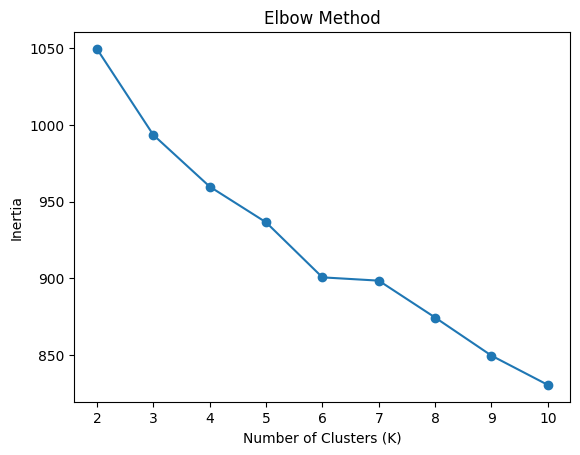

In [27]:
import matplotlib.pyplot as plt

plt.plot(range(2, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [28]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(cluster_data)

    score = silhouette_score(cluster_data, labels)
    silhouette_scores.append(score)

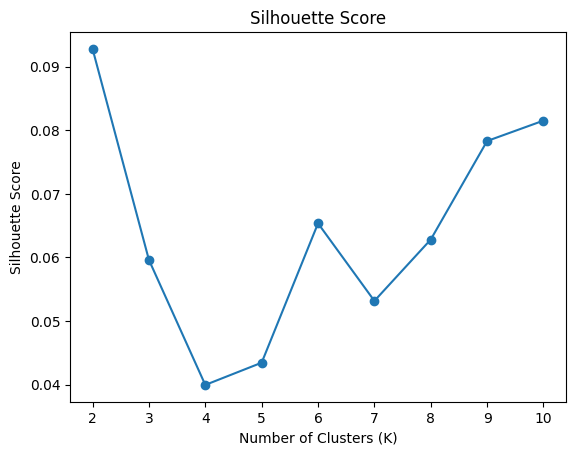

In [29]:
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.show()

In [30]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

cluster_labels = kmeans.fit_predict(cluster_data)

In [31]:
new_data['cluster'] = cluster_labels

In [32]:
new_data['cluster'].value_counts()

cluster
0    84
1    69
Name: count, dtype: int64

In [33]:
new_data.groupby('cluster')['avg_experience'].mean()

cluster
0    8.517857
1    3.956522
Name: avg_experience, dtype: float64

In [34]:
cluster_skill_means = skill_df.groupby(new_data['cluster']).mean()

In [35]:
cluster_skill_means

,3d,administration,advanced analytics,advanced sql,aerospace,agentic ai,agile,agile development,agile scrum,ai,...,vector databases,version control,vertex,vertex ai,vision,visualization,vmware,web services,xgboost,xml
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.000000,0.011905,0.011905,0.011905,0.000000,0.059524,0.011905,0.000000,0.02381,0.023810,...,0.000000,0.000000,0.02381,0.02381,0.000000,0.000000,0.011905,0.02381,0.000000,0.000000
1,0.014493,0.000000,0.086957,0.000000,0.014493,0.014493,0.086957,0.014493,0.00000,0.246377,...,0.014493,0.028986,0.00000,0.00000,0.014493,0.028986,0.000000,0.00000,0.014493,0.014493


In [36]:
top_skills_cluster0 = cluster_skill_means.loc[0].sort_values(ascending=False).head(10)

top_skills_cluster0

machine learning               0.833333
python                         0.607143
data                           0.416667
data science                   0.392857
natural language processing    0.321429
artificial intelligence        0.309524
machine                        0.226190
deep learning                  0.166667
generative ai                  0.166667
data scientist                 0.154762
Name: 0, dtype: float64

In [37]:
top_skills_cluster1 = cluster_skill_means.loc[1].sort_values(ascending=False).head(10)

top_skills_cluster1

machine learning               0.449275
python                         0.333333
ai                             0.246377
data science                   0.188406
artificial intelligence        0.188406
analytics                      0.173913
data analysis                  0.159420
sql                            0.144928
natural language processing    0.130435
algorithms                     0.130435
Name: 1, dtype: float64

In [38]:
skill_difference = (
    cluster_skill_means.loc[0] -
    cluster_skill_means.loc[1]
).sort_values(ascending=False)

In [39]:
skill_difference.head(10)

machine learning               0.384058
data                           0.315217
python                         0.273810
data science                   0.204451
natural language processing    0.190994
machine                        0.168219
generative ai                  0.123188
artificial intelligence        0.121118
deep learning                  0.108696
aiml                           0.083333
dtype: float64

In [40]:
skill_difference.tail(10)

ai solutions         -0.072464
mathematics          -0.072464
azure                -0.075052
agile                -0.075052
advanced analytics   -0.075052
automation           -0.086957
data pipelines       -0.086957
algorithms           -0.106625
analytics            -0.138199
ai                   -0.222567
dtype: float64

In [41]:
top_cluster0 = skill_difference.head(10)

In [42]:
top_cluster1 = skill_difference.tail(10).sort_values()

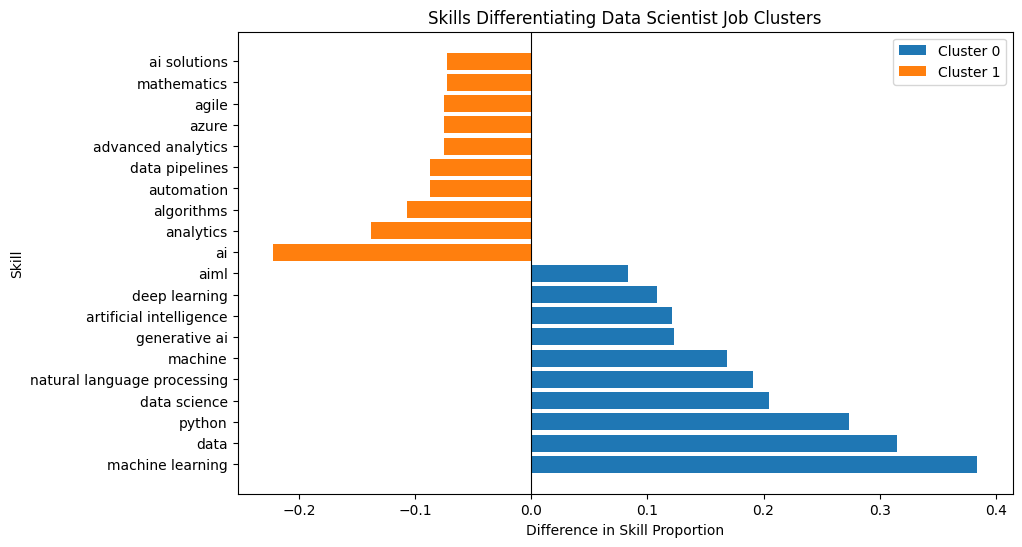

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_cluster0.index,
    top_cluster0.values,
    label="Cluster 0"
)

plt.barh(
    top_cluster1.index,
    top_cluster1.values,
    label="Cluster 1"
)

plt.axvline(0, color='black', linewidth=0.8)

plt.xlabel("Difference in Skill Proportion")
plt.ylabel("Skill")
plt.title("Skills Differentiating Data Scientist Job Clusters")
plt.legend()

plt.show()

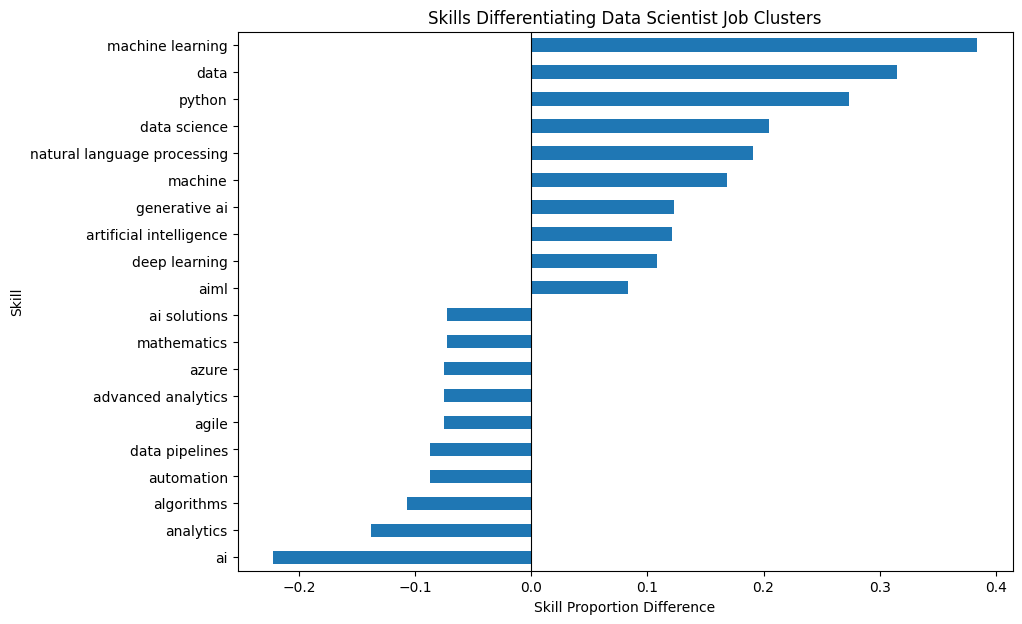

In [44]:
plt.figure(figsize=(10, 7))

diff_to_plot = pd.concat([
    skill_difference.head(10),
    skill_difference.tail(10)
])

diff_to_plot.sort_values().plot(kind='barh')

plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Skill Proportion Difference")
plt.ylabel("Skill")
plt.title("Skills Differentiating Data Scientist Job Clusters")
plt.show()

In [45]:
##company specific analysis
data['company'].nunique()

86

In [46]:
data['company'].value_counts()

company
Tata Consultancy Services    21
IBM                           9
Conduent                      7
PwC                           4
Celebal Technologies          4
                             ..
Pjsofttech                    1
Aditya Birla Insulators       1
Apex Group                    1
KSB                           1
Accenture                     1
Name: count, Length: 86, dtype: int64

In [47]:
top_companies=data['company'].value_counts().head(20)
top_companies

company
Tata Consultancy Services      21
IBM                             9
Conduent                        7
PwC                             4
Celebal Technologies            4
Ford                            4
LTM                             4
Amgen Inc                       4
Genpact                         4
Ciklum                          3
Wabtec                          3
Altimetrik                      2
Aon                             2
Happiest Minds Technologies     2
Net Connect                     2
Praxis Consultants              2
Capco                           2
WNS Holdings                    2
Ecolab Global Services          2
Siemens                         2
Name: count, dtype: int64

In [48]:
company_skill_means = skill_df.groupby(
    data['company']
).mean()

In [49]:
company_skill_means_top = company_skill_means.loc[
    top_companies.index
]

In [50]:
company_counts = data['company'].value_counts()

selected_companies = company_counts[company_counts >= 3]

selected_companies

company
Tata Consultancy Services    21
IBM                           9
Conduent                      7
PwC                           4
Celebal Technologies          4
Ford                          4
LTM                           4
Amgen Inc                     4
Genpact                       4
Ciklum                        3
Wabtec                        3
Name: count, dtype: int64

In [51]:
company_skill_means = skill_df.groupby(
    data['company']
).mean()

In [52]:
company_skill_means = company_skill_means.loc[
    selected_companies.index
]

In [53]:
company_skill_means.loc['Tata Consultancy Services'] \
    .sort_values(ascending=False).head(10)

machine learning               0.952381
data                           0.666667
python                         0.619048
artificial intelligence        0.571429
data science                   0.523810
machine                        0.523810
natural language processing    0.333333
intelligence                   0.285714
science                        0.285714
deep learning                  0.238095
Name: Tata Consultancy Services, dtype: float64

In [54]:
import joblib
joblib.dump(kmeans,"Model.pkl")

['Model.pkl']

In [55]:
joblib.dump(m, "skill_encoder.pkl")

['skill_encoder.pkl']

In [56]:
joblib.dump(scaler, "experience_scaler.pkl")

['experience_scaler.pkl']